# Task 3: Monthly Spending
CPE342 Karena Thailand Player Intelligence. Zero-inflated regression, target `spending_30d`, metric NMAE score $1/(1+\sum|y-\hat y|/\sum y)$.

This notebook is the Task 3 slice of `CPE342_Master_Pipeline.ipynb`: the same cells, the same shared code in `src/` and the same cached artefacts in `outputs/`, so both produce identical predictions. It ends by writing `outputs/submission_parts/task3.csv`; `python scripts/make_submission.py` joins the five parts into `submission.csv`.

**Rules followed.** Only the provided data are used; test rows are only ever predicted; every score and decision comes from 5-fold out-of-fold validation, and the final models are retrained on Train+Val combined; models are trained from scratch; no AutoML (Optuna for tuning); no leaderboard probing.

## Table of Contents
1. [Imports & Configuration](#1)
2. [Data Loading & Overview](#2)
3. [Exploratory Data Analysis](#3)
4. [Data Preparation & Feature Engineering](#4)
5. [Model Training & Evaluation](#5)
6. [Hyperparameter Tuning](#6)
7. [Stacking Ensemble (K-Fold) & Final Decision](#7)
8. [Feature Importance Analysis](#8)
9. [Submission](#9)
10. [Conclusion](#10)

<a id="1"></a>
# 1. Imports & Configuration

Global seeds, warning suppression, GPU discovery, and the exact competition metric, checked on toy inputs.

In [1]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in taskN/; the shared code is one level up
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as C
from src.config import SEED, N_FOLDS, FBETA_AVERAGE
from src.utils import seed_everything, quiet, reduce_mem_usage, timer, save_preds, load_preds, load_params
from src.metrics import (fbeta, f2, f3, macro_f1, nmae, optimize_threshold, threshold_curve,
                         optimize_class_weights, apply_class_weights)
from src.modeling import make_folds, run_cv, run_cv_sklearn
from src import viz
from src.viz import CAT, SEQ_CMAP, DIV_CMAP, MUTED, savefig

quiet()
seed_everything(SEED)
viz.set_theme()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

import torch, lightgbm, xgboost, catboost, sklearn, optuna
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | catboost {catboost.__version__} | sklearn {sklearn.__version__} | optuna {optuna.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
AVG_NAME = "positive-class" if FBETA_AVERAGE == "binary" else "macro"
print(f"SEED={SEED}  N_FOLDS={N_FOLDS}  FBETA_AVERAGE={FBETA_AVERAGE!r}")

# Execution switches: heavy artifacts are cached in outputs/ and re-used unless forced.
RUN_OPTUNA = False          # True -> (re)run Optuna studies in-notebook (slow); False -> load stored studies
RUN_T4_TRAINING = False     # True -> launch the Task 4 GPU K-fold fine-tuning if fold caches are missing

python 3.14.6 | torch 2.14.1+cu130 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1 | optuna 5.0.0
device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU
SEED=42  N_FOLDS=5  FBETA_AVERAGE='binary'


In [2]:
# Sanity-check the metric implementations on toy inputs
y_t = np.array([1, 1, 1, 0, 0, 0, 0, 0])
y_p = np.array([1, 1, 0, 1, 0, 0, 0, 0])
P, R = 2 / 3, 2 / 3
assert abs(fbeta(y_t, y_p, 2, "binary") - 5 * P * R / (4 * P + R)) < 1e-12
assert abs(fbeta(y_t, y_p, 3, "binary") - 10 * P * R / (9 * P + R)) < 1e-12
assert abs(nmae([0, 10, 30], [5, 10, 20]) - 1 / (1 + 15 / 40)) < 1e-12
print("metric checks passed | macro-F2 toy:", round(f2(y_t, y_p, 'macro'), 4), "| binary-F2 toy:", round(f2(y_t, y_p, 'binary'), 4))

metric checks passed | macro-F2 toy: 0.7333 | binary-F2 toy: 0.6667


<a id="2"></a>
# 2. Data Loading & Overview

Row *i* of `test.csv` maps positionally to submission id `ANS{i:05d}` (25,889 rows).

**Data card.**
* **Task 3** has 32 numeric features, including `segment` from Task 2. The target is in THB, with 48% exact zeros and a long right tail (max 300k).

In [3]:
from src import task3
t3_train, t3_test = task3.load()
reduce_mem_usage(t3_train, verbose=True)
seg_names = ["Casual", "Grinder", "Social", "Whale"]
display(pd.DataFrame({"train rows": [len(t3_train)], "test rows": [len(t3_test)], "features": [t3_test.shape[1] - 1],
                      "zero share": [(t3_train.spending_30d == 0).mean()], "missing rate": [t3_train.drop(columns="spending_30d").isna().mean().mean()]}))

memory 31.7 MB -> 20.2 MB (36% saved)


,train rows,test rows,features,zero share,missing rate
0,104000,25889,32,0.4812,0.0564


<a id="3"></a>
# 3. Exploratory Data Analysis

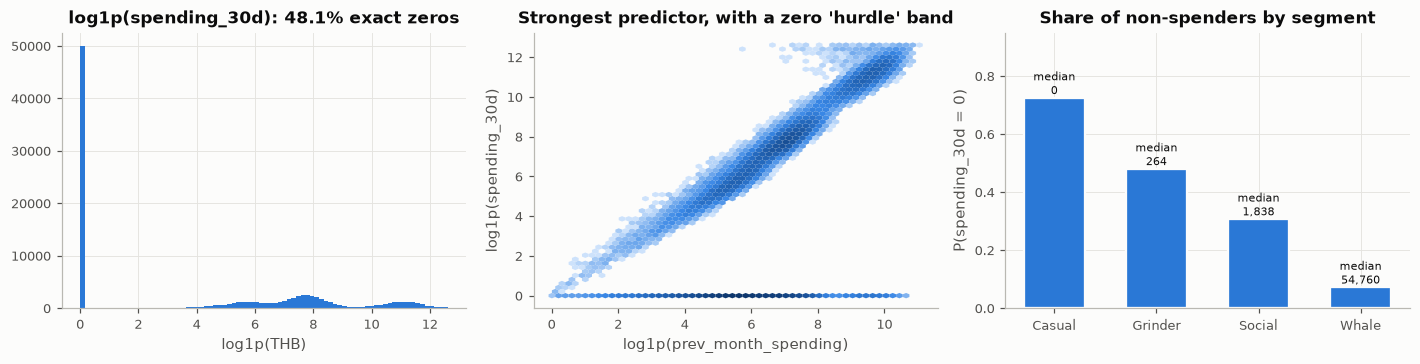

skewness of y: 4.17 | quantiles of positive y: {0.1: 194.0, 0.5: 2314.0, 0.9: 74062.0, 0.99: 184399.0}


Top correlations with target: {'historical_spending': 0.867, 'prev_month_spending': 0.865, 'segment': 0.567, 'event_participation_rate': 0.498, 'vip_status': 0.443, 'is_premium_member': 0.414}


In [4]:
y3 = t3_train.spending_30d
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].hist(np.log1p(y3), bins=80, color=CAT[0])
axes[0].set_title(f"log1p(spending_30d): {(y3 == 0).mean():.1%} exact zeros")
axes[0].set_xlabel("log1p(THB)")
hb = axes[1].hexbin(np.log1p(t3_train.prev_month_spending), np.log1p(y3), gridsize=55, cmap=SEQ_CMAP, bins="log", mincnt=1)
axes[1].set_xlabel("log1p(prev_month_spending)"); axes[1].set_ylabel("log1p(spending_30d)")
axes[1].set_title("Strongest predictor, with a zero 'hurdle' band"); axes[1].grid(False)
seg = t3_train.groupby("segment").spending_30d.agg(zero_rate=lambda s: (s == 0).mean(), median="median")
axes[2].bar(seg_names, seg["zero_rate"], color=CAT[0], width=0.6, **viz.bar_gap())
for i, (zr, m) in enumerate(zip(seg["zero_rate"], seg["median"])):
    axes[2].text(i, zr, f"median\n{m:,.0f}", ha="center", va="bottom", fontsize=7.5)
axes[2].set_ylim(0, 0.95); axes[2].set_title("Share of non-spenders by segment"); axes[2].set_ylabel("P(spending_30d = 0)")
plt.tight_layout(); savefig(fig, "t3_eda_target"); plt.show()
print("skewness of y:", round(y3.skew(), 2), "| quantiles of positive y:", y3[y3 > 0].quantile([.1, .5, .9, .99]).round(0).to_dict())
print("Top correlations with target:", t3_train.drop(columns="player_id").corr()["spending_30d"].drop("spending_30d").sort_values(ascending=False).head(6).round(3).to_dict())

**Findings.** The target is **zero-inflated** (48% zeros) and **heavily right-skewed** (skew ≈ 4.2). Past spending (`historical_spending`, `prev_month_spending`, ρ ≈ 0.87) dominates. Among spenders, log-spend follows log prev-month spend in a tight band. So *how much* a spender spends is very predictable, and the hard part is the **zero hurdle**: whether they spend at all. The segment from Task 2 is the next strongest signal: 72% of Casuals spend nothing, while Whales have a median of ~55k THB. Because NMAE is an absolute-error metric, the zero mass matters. Any account whose probability of spending is below 50% should be predicted as exactly 0.

<a id="4"></a>
# 4. Data Preparation & Feature Engineering

## 4.3 Task 3: RFM proxies and monetary interactions
Recency (`days_since_last_purchase`, recency ratios), frequency (`purchase_frequency`, transactions, sessions) and monetary terms (`log_hist`, `log_prev`, `prev_over_hist`, `hist_per_streak = historical_spending / daily_login_streak`, `txn_value_x_freq`), engagement × event terms (`event_x_session = event_participation_rate · avg_session_length`), and polynomial interactions of past spending (`prev_sq`, `prev_x_hist`, `prev_x_segment`).

In [5]:
X3, y3, X3_test = task3.build(t3_train, t3_test)
new3 = [c for c in X3.columns if c not in t3_train.columns]
spear = X3[new3].corrwith(pd.Series(y3), method="spearman").sort_values(key=np.abs, ascending=False)
print(f"Task 3 matrix: {X3.shape}")
display(spear.to_frame("Spearman rho with spending_30d").T.round(3))

Task 3 matrix: (104000, 52)


,prev_x_segment,log_prev,prev_sq,prev_x_hist,log_hist,monetary_mean_log,hist_x_event,hist_per_age,hist_per_streak,hist_per_txn,log_txn_value_x_freq,txn_value_x_freq,event_x_session,vip_x_premium,purchase_recency_x_freq,weekly_minutes,recency_ratio,discount_share,prev_over_hist,n_missing
Spearman rho with spending_30d,0.6680,0.6520,0.6520,0.6520,0.6510,0.6470,0.6360,0.5770,0.5550,0.5490,0.5420,0.5420,0.4380,0.4210,0.2100,0.1730,-0.1410,0.0550,0.0260,-0.0000


<a id="5"></a>
# 5. Model Training & Evaluation

**Validation protocol.** 5 folds (seed 42), `StratifiedKFold` on a zero / positive-quantile bin of `spending_30d`, so every fold has the same share of non-spenders and whales. Every model produces out-of-fold (OOF) predictions for every training row: they give honest scores, feed threshold/weight tuning and serve as stacking inputs. Test predictions average the 5 fold models. Results are cached in `outputs/preds/*.npz`; delete a file to retrain that model.

In [6]:
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer

folds3 = make_folds(y3, kind="regression")
print("zero share per fold:", [round((y3[v] == 0).mean(), 3) for _, v in folds3])

def cached(name, fn, force=False):
    # Return {'oof','test',...} arrays, training via fn() only when no cache exists.
    r = load_preds(name)
    if r is None or force:
        t0 = time.time()
        out = fn()
        r = {k: np.asarray(v) for k, v in out.items() if k in ("oof", "test", "p_oof", "mu_oof", "p_test", "mu_test", "sigma", "smear", "n_iter")}
        save_preds(name, **r)
        print(f"  trained {name} in {time.time() - t0:.0f}s")
    return r

BASE = {"learning_rate": 0.05}
summary = []   # running scoreboard

zero share per fold: [np.float64(0.481), np.float64(0.481), np.float64(0.481), np.float64(0.481), np.float64(0.481)]


### 5.1 Baseline and feature-engineering ablation (default LightGBM)

In [7]:
raw3 = [c for c in t3_train.columns if c not in ("player_id", "spending_30d")]
b = {}
b["T3 raw (L1 log1p)"] = cached("t3_base_raw_log", lambda: run_cv("lgb", "regression", BASE, X3[raw3], np.log1p(y3), X3_test[raw3], folds3, name="T3 raw log"))
b["T3 FE (L1 log1p)"] = cached("t3_base_fe_log", lambda: run_cv("lgb", "regression", BASE, X3, np.log1p(y3), X3_test, folds3, name="T3 FE log"))
b["T3 FE (L1 raw THB)"] = cached("t3_base_fe_raw", lambda: run_cv("lgb", "regression", BASE, X3, y3, X3_test, folds3, name="T3 FE raw"))
display(pd.DataFrame([[k, "NMAE", nmae(y3, np.clip(b[k]["oof"] if "raw THB" in k else np.expm1(b[k]["oof"]), 0, None))] for k in b],
                     columns=["experiment", "metric", "OOF score"]))

,experiment,metric,OOF score
0,T3 raw (L1 log1p),NMAE,0.7779
1,T3 FE (L1 log1p),NMAE,0.7796
2,T3 FE (L1 raw THB),NMAE,0.7846


**Reading the ablation**

* **Task 3:** feature engineering helps. More interesting, **the L1 model fitted on raw THB beats the L1 model fitted on `log1p`**, although both estimate the conditional median. In log space every account's error weighs the same. On the raw scale, model capacity flows to the whales who dominate $\sum|y-\hat y|$, and that sum is exactly what NMAE measures.

<a id="6"></a>
# 6. Hyperparameter Tuning

Optuna's multivariate **Tree-structured Parzen Estimator** (Bayesian optimisation) searches each model's space, and each trial is scored with the task's **exact** metric on 3-fold OOF predictions:

* **Task 3:** NMAE of the L1 (median) model on raw THB.

Studies run from `scripts/tune.py` (via `scripts/run_tuning.sh`) and persist in `outputs/optuna.db`. This section loads them, and runs them first if `RUN_OPTUNA=True`. Final models use the tuned parameters with **half the tuned learning rate** (early stopping then finds proportionally more trees), which usually adds a little accuracy at no tuning cost.

In [8]:
STORAGE = f"sqlite:///{(C.OUT / 'optuna.db').as_posix()}"
optuna.logging.set_verbosity(optuna.logging.WARNING)
STUDIES = [(3, "lgb", 30)]   # LightGBM is the primary learner; XGB/CatBoost keep robust defaults
studies, rows = {}, []
for t, m, n in STUDIES:
    name = f"task{t}_{m}"
    if RUN_OPTUNA:
        subprocess.run([sys.executable, "-u", "scripts/tune.py", "--task", str(t), "--model", m, "--trials", str(n)], check=True)
    try:
        st = optuna.load_study(study_name=name, storage=STORAGE)
    except KeyError:
        st = None
    studies[name] = st
    if st is not None and len(st.trials):
        done = [tr for tr in st.trials if tr.state.name == "COMPLETE"]
        rows.append([name, len(done), st.best_value, done[0].value, json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in st.best_params.items()})])
display(pd.DataFrame(rows, columns=["study", "trials", "best OOF score", "first-trial score", "best params"]))

,study,trials,best OOF score,first-trial score,best params
0,task3_lgb,30,0.7845,0.7809,"{""learning_rate"": 0.0456, ""num_leaves"": 21, ""m..."


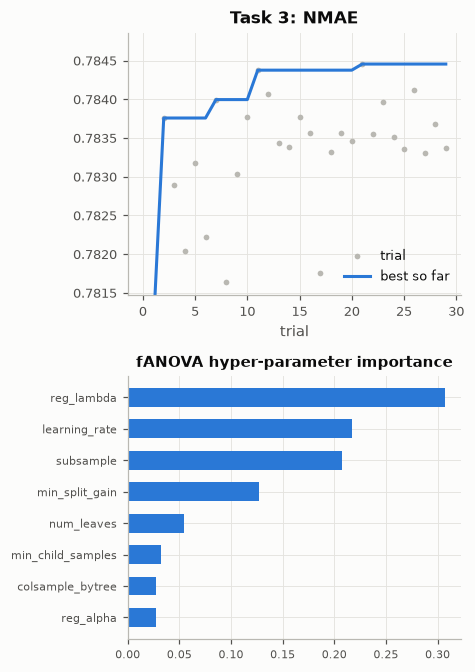

In [9]:
lgb_studies = [s for s in ("task3_lgb",) if studies.get(s) is not None]
fig, axes = plt.subplots(2, len(lgb_studies), figsize=(4.4 * len(lgb_studies), 6.2), squeeze=False)
labels = {"task1_lgb": "Task 1: F2 (study objective: macro)", "task2_lgb": "Task 2: macro-F1", "task3_lgb": "Task 3: NMAE"}
for j, s in enumerate(lgb_studies):
    df = studies[s].trials_dataframe().query("state == 'COMPLETE'")
    ax = axes[0, j]
    ax.scatter(df.number, df.value, s=14, color=MUTED, label="trial")
    ax.plot(df.number, df.value.cummax(), color=CAT[0], lw=2, label="best so far")
    ax.set_title(labels[s]); ax.set_xlabel("trial")
    lo = df.value.quantile(0.1); ax.set_ylim(lo - (df.value.max() - lo) * 0.1, df.value.max() + (df.value.max() - lo) * 0.15)
    imp = optuna.importance.get_param_importances(studies[s])
    imp = pd.Series(imp).sort_values()
    axes[1, j].barh(imp.index, imp.values, color=CAT[0], height=0.6)
    axes[1, j].set_title("fANOVA hyper-parameter importance", fontsize=10); axes[1, j].tick_params(labelsize=7.5)
axes[0, 0].legend(loc="lower right")
plt.tight_layout(); savefig(fig, "optuna"); plt.show()

In [10]:
def tuned(name, fallback):
    p = load_params(name)                                   # written when a study completes
    if p is None and studies.get(name) is not None and len(studies[name].trials):
        p = studies[name].best_params                       # partially-run study: best trial so far
    p = dict(fallback) if p is None else dict(p)
    if "learning_rate" in p:
        p["learning_rate"] = p["learning_rate"] / 2      # finer steps for the final fit
    return p


P3_lgb = tuned("task3_lgb", {"learning_rate": 0.05})
P3_xgb = tuned("task3_xgb", {"learning_rate": 0.05, "max_depth": 7})
shown = [("P3_lgb", P3_lgb), ("P3_xgb", P3_xgb)]
for name, v in shown:
    print(f"{name}: {json.dumps({a: (round(b, 4) if isinstance(b, float) else b) for a, b in v.items()})}")

P3_lgb: {"learning_rate": 0.0228, "num_leaves": 21, "min_child_samples": 22, "colsample_bytree": 0.5483, "subsample": 0.7425, "reg_alpha": 0.0084, "reg_lambda": 16.5506, "min_split_gain": 0.2063}
P3_xgb: {"learning_rate": 0.025, "max_depth": 7}


<a id="7"></a>
# 7. Stacking Ensemble (K-Fold) & Final Decision

Level-1 regressors are blended with non-negative weights that minimise total absolute error (fitted out-of-fold), followed by a median-consistent zero gate and one scale factor.

## 7.3 Task 3: Monthly spending (NMAE)
The level-1 pool mixes *median* estimators (the right target for absolute error) with structured alternatives:

* **L1 GBDTs on raw THB** (LightGBM, XGBoost, CatBoost-MAE) and **L1 LightGBM on `log1p`**.
* **Two-stage hurdle (Cragg, 1971).** A classifier gives $p=P(y>0)$, and an L1 regressor on $\log(1+y)$ is fitted on spenders only. They are combined three ways:
  * **Mixture median** (MAE-optimal under a log-normal positive part): $\hat y = 0$ if $p\le 0.5$, else $\exp\!\big(\mu+\sigma\,\Phi^{-1}(1-\tfrac{0.5}{p})\big)-1$. The scale $\sigma$ and a gate shift are tuned on OOF NMAE.
  * **Hard gate:** $\hat y = 1[p>\tau]\,(e^{\mu}-1)$, with $\tau$ tuned on OOF.
  * **Expected value with Duan smearing,** $p\,(e^{\mu}\bar{e^{\varepsilon}}-1)$. This is the MSE-optimal recipe, shown for contrast.
* **Tweedie GBDT** ($p=1.5$, log link): a mean estimator.

These are blended with **non-negative weights that minimise total absolute error**, with the weights fitted out-of-fold. Two light post-processing steps follow:
* a **median-consistent zero gate:** wherever the hurdle classifier gives $P(y>0)\le 0.5$, the conditional median is exactly 0, so the prediction is set to 0;
* a single scale factor.

In [11]:
m3 = {}
r = cached("t3_lgb_raw", lambda: run_cv("lgb", "regression", P3_lgb, X3, y3, X3_test, folds3, name="T3 lgb L1 raw"))
m3["LGB-L1 raw THB"] = (np.clip(r["oof"], 0, None), np.clip(r["test"], 0, None))
r = cached("t3_xgb_raw", lambda: run_cv("xgb", "regression", P3_xgb, X3, y3, X3_test, folds3, name="T3 xgb L1 raw"))
m3["XGB-L1 raw THB"] = (np.clip(r["oof"], 0, None), np.clip(r["test"], 0, None))
r = cached("t3_cat_raw", lambda: run_cv("cat", "regression", {"learning_rate": 0.08, "depth": 8}, X3, y3, X3_test, folds3, name="T3 cat MAE"))
m3["Cat-MAE raw THB"] = (np.clip(r["oof"], 0, None), np.clip(r["test"], 0, None))
r = cached("t3_lgb_log", lambda: run_cv("lgb", "regression", P3_lgb, X3, np.log1p(y3), X3_test, folds3, name="T3 lgb L1 log"))
m3["LGB-L1 log1p"] = (np.clip(np.expm1(r["oof"]), 0, None), np.clip(np.expm1(r["test"]), 0, None))
r = cached("t3_tweedie", lambda: run_cv("lgb", "regression", {"learning_rate": 0.05, "objective": "tweedie", "tweedie_variance_power": 1.5, "metric": "l1"},
                                        X3, y3, X3_test, folds3, name="T3 tweedie"))
m3["LGB-Tweedie (mean)"] = (np.clip(r["oof"], 0, None), np.clip(r["test"], 0, None))

h = cached("t3_hurdle", lambda: task3.hurdle_cv("lgb", X3, y3, X3_test, folds3, clf_params={"learning_rate": 0.05},
                                                reg_params={"learning_rate": 0.05}))
sigma0, smear = float(h["sigma"]), float(h["smear"])
tm = task3.tune_mixture(y3, h["p_oof"], h["mu_oof"], sigma0)
m3["Hurdle mixture-median"] = (task3.mixture_median(np.clip(h["p_oof"] + tm["shift"], 0, 1), h["mu_oof"], tm["sigma"]),
                               task3.mixture_median(np.clip(h["p_test"] + tm["shift"], 0, 1), h["mu_test"], tm["sigma"]))
th = task3.tune_hard_hurdle(y3, h["p_oof"], h["mu_oof"])
m3["Hurdle hard gate"] = (task3.hard_hurdle(h["p_oof"], h["mu_oof"], th["tau"]), task3.hard_hurdle(h["p_test"], h["mu_test"], th["tau"]))
m3["Hurdle E[y] + smearing"] = (task3.expected_value(h["p_oof"], h["mu_oof"], smear), task3.expected_value(h["p_test"], h["mu_test"], smear))
print(f"hurdle: robust sigma={sigma0:.3f} -> tuned {tm['sigma']:.3f}, gate shift {tm['shift']:+.3f}; hard-gate tau={th['tau']:.3f}; smearing factor={smear:.3f}")
print(f"stage-1 AUC P(y>0): {roc_auc_score(y3 > 0, h['p_oof']):.4f}")

hurdle: robust sigma=0.177 -> tuned 0.158, gate shift +0.001; hard-gate tau=0.520; smearing factor=1.052
stage-1 AUC P(y>0): 0.7845


,NMAE
model,
LGB-L1 raw THB,0.78531
XGB-L1 raw THB,0.78523
Cat-MAE raw THB,0.77947
LGB-L1 log1p,0.78159
LGB-Tweedie (mean),0.77644
Hurdle mixture-median,0.78830
Hurdle hard gate,0.78720
Hurdle E[y] + smearing,0.78521
L1 blend (out-of-fold weights),0.78888


full-data blend weights: {'LGB-L1 raw THB': 0.057, 'XGB-L1 raw THB': 0.207, 'Cat-MAE raw THB': 0.044, 'LGB-Tweedie (mean)': 0.059, 'Hurdle mixture-median': 0.367, 'Hurdle hard gate': 0.268}


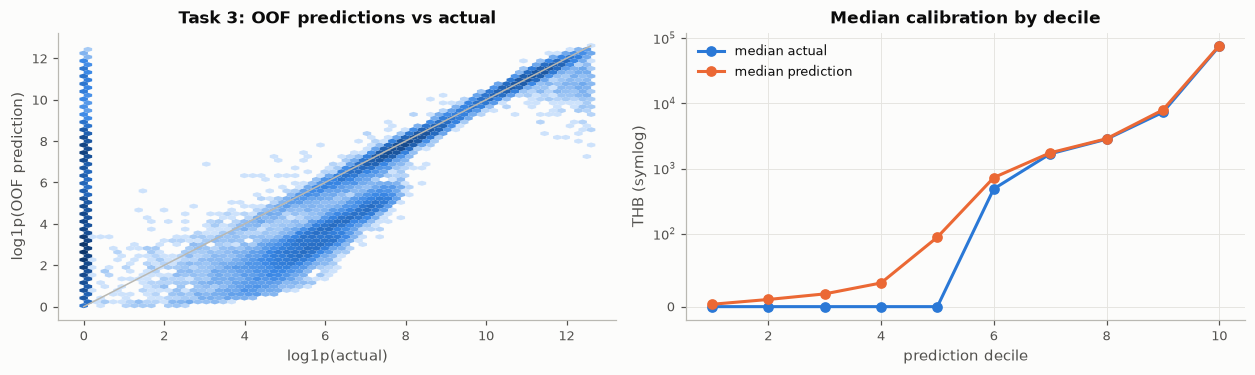

In [12]:
names3 = list(m3)
P3o = np.column_stack([m3[k][0] for k in names3])
P3t = np.column_stack([m3[k][1] for k in names3])

# out-of-fold blending: weights fitted on 4 folds' OOF predictions, applied to the 5th
blend_oof = np.zeros(len(y3))
for tr, va in folds3:
    w = task3.l1_blend_weights(y3[tr], [P3o[tr, j] for j in range(P3o.shape[1])])
    blend_oof[va] = P3o[va] @ w
W3 = task3.l1_blend_weights(y3, [P3o[:, j] for j in range(P3o.shape[1])])
# median-consistent zero gate: if P(y>0) <= 0.5 the conditional median is exactly 0
gate_oof = (np.clip(h["p_oof"] + tm["shift"], 0, 1) > 0.5).astype(float)
gate_test = (np.clip(h["p_test"] + tm["shift"], 0, 1) > 0.5).astype(float)
scales = np.linspace(0.85, 1.15, 61)
sc_scores = [nmae(y3, blend_oof * s * gate_oof) for s in scales]
SCALE3 = float(scales[int(np.argmax(sc_scores))])
SCORE3 = nmae(y3, blend_oof * SCALE3 * gate_oof)
pred3 = np.clip(P3t @ W3 * SCALE3, 0, None) * gate_test

rows = [[k, nmae(y3, m3[k][0])] for k in names3]
rows += [["L1 blend (out-of-fold weights)", nmae(y3, blend_oof)],
         ["+ zero gate (P(y>0) <= 0.5 -> 0)", nmae(y3, blend_oof * gate_oof)],
         [f"+ scale {SCALE3:.3f} (final)", SCORE3]]
display(pd.DataFrame(rows, columns=["model", "NMAE"]).set_index("model").style.format("{:.5f}").highlight_max(props="font-weight:bold"))
print("full-data blend weights:", {k: round(float(w), 3) for k, w in zip(names3, W3) if w > 1e-3})
summary.append(["Task 3", "NMAE", SCORE3, "L1/hurdle/Tweedie pool -> OOF L1 blend -> median zero gate -> scale"])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
hb = axes[0].hexbin(np.log1p(y3), np.log1p(blend_oof * SCALE3), gridsize=60, cmap=SEQ_CMAP, bins="log", mincnt=1)
axes[0].plot([0, 12.6], [0, 12.6], color=MUTED, lw=1); axes[0].grid(False)
axes[0].set_xlabel("log1p(actual)"); axes[0].set_ylabel("log1p(OOF prediction)"); axes[0].set_title("Task 3: OOF predictions vs actual")
dec = pd.qcut(blend_oof * SCALE3, 10, labels=False, duplicates="drop")
calib = pd.DataFrame({"pred": blend_oof * SCALE3, "y": y3, "d": dec}).groupby("d").agg(pred=("pred", "median"), y=("y", "median"))
axes[1].plot(calib.index + 1, calib.y, marker="o", color=CAT[0], label="median actual")
axes[1].plot(calib.index + 1, calib.pred, marker="o", color=CAT[1], label="median prediction")
axes[1].set_yscale("symlog", linthresh=100); axes[1].set_xlabel("prediction decile"); axes[1].set_ylabel("THB (symlog)")
axes[1].set_title("Median calibration by decile"); axes[1].legend()
plt.tight_layout(); savefig(fig, "t3_calibration"); plt.show()

## 7.6 Final model: combine Train+Val (competition rule)
The rules say: *"Combine Train+Val for training"* and *"✅ Allowed: combining Train and Validation sets for final model training after all validation is complete."* Everything above was validation: the 5-fold OOF predictions are what we scored, tuned and stacked on. Each fold model saw only 80% of the labelled data. Now, with every decision fixed, each level-1 model is **retrained once on 100% of the labelled rows**:

* **GBDTs:** the validated hyper-parameters are reused. The number of boosting rounds comes from early stopping on fold 0, ×1.15 for the 25% larger training set, so no hold-out is needed.
* **ExtraTrees / logistic regression / hurdle stages:** refitted on all rows.

The final level-1 test input is the **average of the 5-fold models and the full-data model**. Both are legitimate final models, and averaging them lowers variance. **Nothing is re-tuned:** the stacker, the threshold τ, the class multipliers, the L1 blend weights, the zero gate and the scale all keep their out-of-fold values. Task 5 has no labelled data, so its detectors are already fitted on all available data.

In [13]:
from src.modeling import refit_full, refit_full_sklearn
FULL_W = 0.5                                     # weight of the full-data model in the final test input
blend_full = lambda fold_test, full_test: (1 - FULL_W) * np.asarray(fold_test) + FULL_W * np.asarray(full_test)
changes = []

# ---- Task 3
r = {}
r["LGB-L1 raw THB"] = cached("t3_lgb_raw_full", lambda: refit_full("lgb", "regression", P3_lgb, X3, y3, X3_test, folds3, name="T3 lgb raw"))
r["XGB-L1 raw THB"] = cached("t3_xgb_raw_full", lambda: refit_full("xgb", "regression", P3_xgb, X3, y3, X3_test, folds3, name="T3 xgb raw"))
r["Cat-MAE raw THB"] = cached("t3_cat_raw_full", lambda: refit_full("cat", "regression", {"learning_rate": 0.08, "depth": 8}, X3, y3, X3_test, folds3, name="T3 cat"))
r["LGB-L1 log1p"] = cached("t3_lgb_log_full", lambda: refit_full("lgb", "regression", P3_lgb, X3, np.log1p(y3), X3_test, folds3, name="T3 lgb log"))
r["LGB-Tweedie (mean)"] = cached("t3_tweedie_full", lambda: refit_full("lgb", "regression", {"learning_rate": 0.05, "objective": "tweedie",
                                 "tweedie_variance_power": 1.5, "metric": "l1"}, X3, y3, X3_test, folds3, name="T3 tweedie"))
hf = cached("t3_hurdle_full", lambda: task3.hurdle_full("lgb", X3, y3, X3_test, folds3, {"learning_rate": 0.05}, {"learning_rate": 0.05}))
full3 = {k: np.clip(v["test"], 0, None) for k, v in r.items()}
full3["LGB-L1 log1p"] = np.clip(np.expm1(r["LGB-L1 log1p"]["test"]), 0, None)
p_fin = blend_full(h["p_test"], hf["p_test"]); mu_fin = blend_full(h["mu_test"], hf["mu_test"])
P3t_final = []
for k in names3:
    if k == "Hurdle mixture-median":
        P3t_final.append(task3.mixture_median(np.clip(p_fin + tm["shift"], 0, 1), mu_fin, tm["sigma"]))
    elif k == "Hurdle hard gate":
        P3t_final.append(task3.hard_hurdle(p_fin, mu_fin, th["tau"]))
    elif k == "Hurdle E[y] + smearing":
        P3t_final.append(task3.expected_value(p_fin, mu_fin, smear))
    else:
        P3t_final.append(blend_full(m3[k][1], full3[k]))
gate_test_final = (np.clip(p_fin + tm["shift"], 0, 1) > 0.5).astype(float)
pred3_final = np.clip(np.column_stack(P3t_final) @ W3 * SCALE3, 0, None) * gate_test_final
changes.append(["Task 3", "corr(log1p before, after)", np.corrcoef(np.log1p(pred3), np.log1p(pred3_final))[0, 1],
                f"zero share {np.mean(pred3 == 0):.3f} -> {np.mean(pred3_final == 0):.3f}"])

display(pd.DataFrame(changes, columns=["task", "check", "value", "note"]).set_index("task").round(4))
pred3 = pred3_final   # used by section 9

,check,value,note
task,,,
Task 3,"corr(log1p before, after)",0.9969,zero share 0.506 -> 0.506


<a id="8"></a>
# 8. Feature Importance Analysis

Exact **TreeSHAP** (Lundberg & Lee) values come from a LightGBM model refit on fold 0 with the tuned parameters, explaining 4,000 held-out rows, complemented by model-agnostic **permutation importance** (the metric drop when a column is shuffled on the held-out fold).

In [14]:
import lightgbm as lgb
from sklearn.inspection import permutation_importance

def fold0_lgb(params, X, y, objective, n_classes=None):
    tr, va = (folds1 if objective == "binary" else folds2 if objective == "multiclass" else folds3)[0]
    from src.modeling import LGB_BASE
    p = {**LGB_BASE, **params, "objective": {"binary": "binary", "multiclass": "multiclass", "regression": "regression_l1"}[objective]}
    Model = lgb.LGBMRegressor if objective == "regression" else lgb.LGBMClassifier
    m = Model(**p).fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])], callbacks=[lgb.early_stopping(200, verbose=False)])
    return m, va

def tree_shap(model, Xs):
    # LightGBM's built-in TreeSHAP (pred_contrib) - exact, handles categoricals; drops the bias column
    c = model.booster_.predict(Xs, pred_contrib=True, num_iteration=model.best_iteration_)
    k = Xs.shape[1] + 1
    return c.reshape(len(Xs), -1, k)[:, :, :-1] if c.shape[1] > k else c[:, :-1]

def shap_panel(ax, sv, Xs, title, top=14):
    imp = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values().tail(top)
    ax.barh(imp.index, imp.values, color=CAT[0], height=0.65)
    ax.set_title(title); ax.set_xlabel("mean |SHAP|"); ax.tick_params(axis="y", labelsize=8)
    return imp

def dependence(ax, sv, Xs, col, color=CAT[0]):
    j = list(Xs.columns).index(col)
    x = Xs[col].values
    lo, hi = np.nanpercentile(x, [0.5, 99.5])
    m = ~np.isnan(x) & (x >= lo) & (x <= hi)
    ax.scatter(x[m], sv[m, j], s=3, alpha=0.35, color=color, rasterized=True)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel(col); ax.set_ylabel("SHAP value")

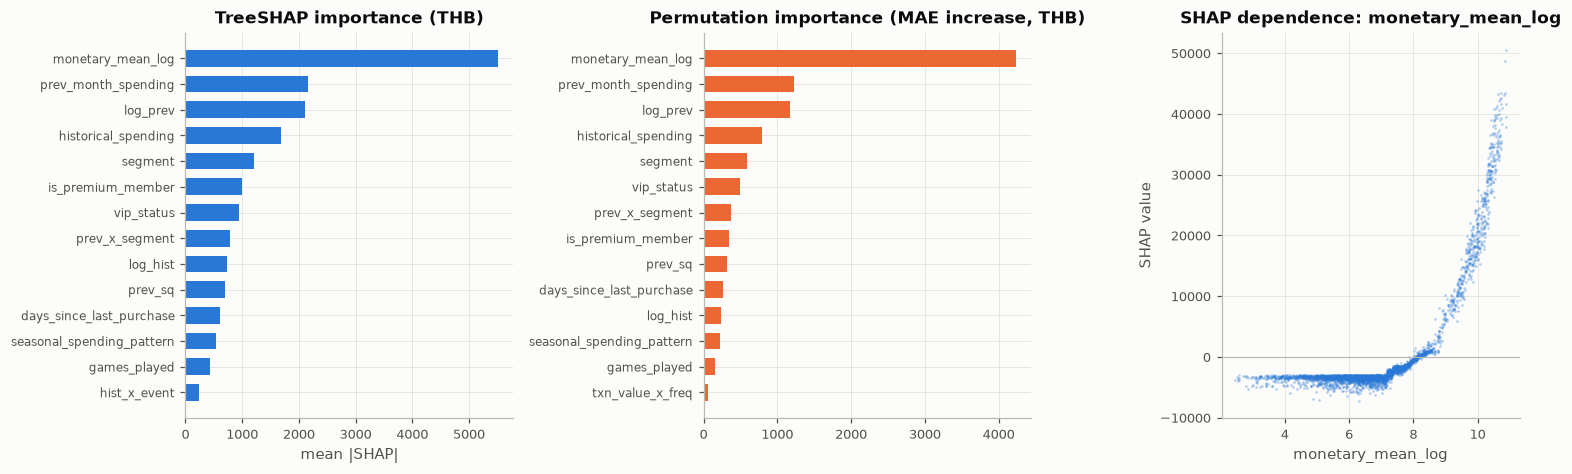

In [15]:
mdl3, va3 = fold0_lgb(P3_lgb, X3, y3, "regression")
Xs3 = X3.iloc[va3].sample(4000, random_state=SEED)
sv3 = tree_shap(mdl3, Xs3)
pi3 = permutation_importance(mdl3, X3.iloc[va3], y3[va3], scoring="neg_mean_absolute_error", n_repeats=3, random_state=SEED, n_jobs=1)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
imp3 = shap_panel(axes[0], sv3, Xs3, "TreeSHAP importance (THB)")
pim3 = pd.Series(pi3.importances_mean, index=X3.columns).sort_values().tail(14)
axes[1].barh(pim3.index, pim3.values, color=CAT[1], height=0.65); axes[1].set_title("Permutation importance (MAE increase, THB)")
axes[1].tick_params(axis="y", labelsize=8)
dependence(axes[2], sv3, Xs3, imp3.index[-1]); axes[2].set_title(f"SHAP dependence: {imp3.index[-1]}")
plt.tight_layout(); savefig(fig, "t3_shap"); plt.show()

**Business reading (spending).** Monetary history dominates. The engineered `monetary_mean_log` (mean of log historical and log previous-month spend) is by far the strongest driver, and its SHAP curve is flat below ~7 (≈1,100 THB) and then rises steeply: only established spenders move the forecast. After it come raw previous-month and historical spend, `segment` (Task 2's output feeds Task 3), premium membership and VIP tier. Days since the last purchase act as a smaller brake. For Karena:
* **VIP desk:** route support by *predicted* 30-day spend rather than playtime. This avoids last quarter's mistake of white-glove service for 150 heavy players who spent little while a 255k-THB whale waited three days.
* **Discount targeting:** accounts whose predicted spend is high *without* any discount do not need a 50% coupon. Concentrate discounts on the predicted-zero/low band with recent activity.
* **Revenue forecasting:** the sum of predicted medians is a conservative, outlier-robust forecast. Pair it with the Tweedie mean model when finance needs an expected-value total.

<a id="9"></a>
# 9. Submission

The Task 3 column of the submission: `task3` is a THB amount rounded to 2 decimals. The part is written to `outputs/submission_parts/task3.csv` with the `id` column of `sample_submission.csv`; `python scripts/make_submission.py` checks and joins the five parts.

In [16]:
sample_sub = pd.read_csv(C.SAMPLE_SUB)
part = pd.DataFrame({"id": sample_sub.id, "task3": np.round(pred3, 2)})
assert len(part) == C.N_TEST == len(t3_test) and part.id.tolist() == [f"ANS{i:05d}" for i in range(1, C.N_TEST + 1)]
assert part["task3"].notna().all() and (part.task3 >= 0).all()
part_dir = C.OUT / "submission_parts"
part_dir.mkdir(exist_ok=True)
part.to_csv(part_dir / "task3.csv", index=False)
print(f"saved {part_dir / 'task3.csv'} | {part.shape}")
display(part.head())
print(f"zero share {(part.task3 == 0).mean():.3f} | median {part.task3.median():,.0f} | mean {part.task3.mean():,.0f} THB")

saved C:\Users\Oping\cpe342-kaggle-main\outputs\submission_parts\task3.csv | (25889, 2)


,id,task3
0,ANS00001,0.0000
1,ANS00002,"2,281.3200"
2,ANS00003,0.0000
3,ANS00004,0.0000
4,ANS00005,0.0000


zero share 0.506 | median 0 | mean 10,430 THB


<a id="10"></a>
# 10. Conclusion

In [17]:
display(pd.DataFrame(summary, columns=["task", "metric", "OOF score", "final recipe"]).set_index("task").style.format({"OOF score": "{:.4f}"}))

,metric,OOF score,final recipe
task,,,
Task 3,NMAE,0.7892,L1/hurdle/Tweedie pool -> OOF L1 blend -> median zero gate -> scale


| Task | Key insight | What moved the score |
|---|---|---|
| 3 Spending | NMAE ⇔ total absolute error ⇒ predict the **median** | L1 GBDTs on raw THB, **hurdle mixture-median**; OOF L1 blend, median-consistent zero gate, scale |